> **Version formatrice.** Tous les exercices sont complétés et le notebook a été exécuté. Les participants utilisent la version à compléter, à la racine du dossier.

# IA101 — Notebook 4 — Améliorer un modèle

**Durée : 30 minutes** · Objectif visé : **O5** — améliorer un modèle de façon rigoureuse

Un premier modèle fonctionne. Comment l'améliorer sans biaiser son évaluation ? Ce notebook présente les principaux leviers et la méthodologie qui permet de les utiliser correctement.

| Levier | Question | Outil |
| --- | --- | --- |
| Complexité du modèle | Le modèle est-il trop simple ou trop complexe ? | Courbe de validation |
| Évaluation fiable | Comment comparer des modèles sans dépendre d'un seul découpage ? | Validation croisée |
| Hyperparamètres | Quels réglages retenir ? | `GridSearchCV` dans un `Pipeline` |
| Quantité de données | Plus de données aideraient-elles ? | Courbe d'apprentissage |

### Données : chiffres manuscrits
1797 images de 8 × 8 pixels représentant les chiffres 0 à 9. Chaque image est représentée par un vecteur de 64 intensités.

In [1]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

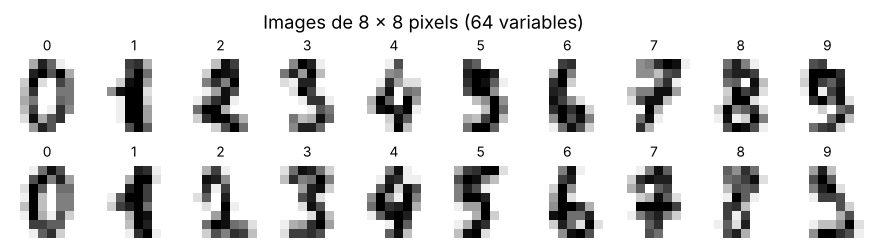

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, learning_curve, validation_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

chiffres = load_digits()
X, y = chiffres.data, chiffres.target
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

fig, axes = plt.subplots(2, 10, figsize=(10, 2.3))
for ax, img, lab in zip(axes.ravel(), chiffres.images, chiffres.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.suptitle("Images de 8 × 8 pixels (64 variables)", y=1.04); plt.show()

## 1. Une erreur méthodologique fréquente

Le code suivant annonce une exactitude de 100 %. **Identifiez le problème** avant de lire l'explication.

In [3]:
arbre = DecisionTreeClassifier(random_state=0)
arbre.fit(X_ent, y_ent)
print(f"Exactitude : {arbre.score(X_ent, y_ent):.1%}")

Exactitude : 100.0%


<details>
<summary><b>Afficher l'explication</b></summary>

Le modèle est évalué sur les **données qui ont servi à l'entraîner**. Cette mesure ne dit rien de sa capacité de généralisation. Sur l'ensemble de test, le résultat est très différent (cellule suivante).
</details>

In [4]:
print(f"Entraînement : {arbre.score(X_ent, y_ent):.1%} | Test : {arbre.score(X_test, y_test):.1%}")

Entraînement : 100.0% | Test : 85.6%


Un écart important entre l'entraînement et le test est la **signature du surapprentissage**.

## 2. Ajuster la complexité : la courbe de validation

La **profondeur maximale** d'un arbre de décision (`max_depth`) contrôle le nombre de questions successives qu'il peut poser, donc sa complexité.

Pour choisir cette profondeur **sans utiliser l'ensemble de test**, on mesure la performance par **validation croisée** sur l'ensemble d'entraînement (principe détaillé à la section 3). `validation_curve` automatise ce calcul.

**Prédiction.** Lorsque la profondeur augmente, comment évoluent les scores d'entraînement et de validation ?

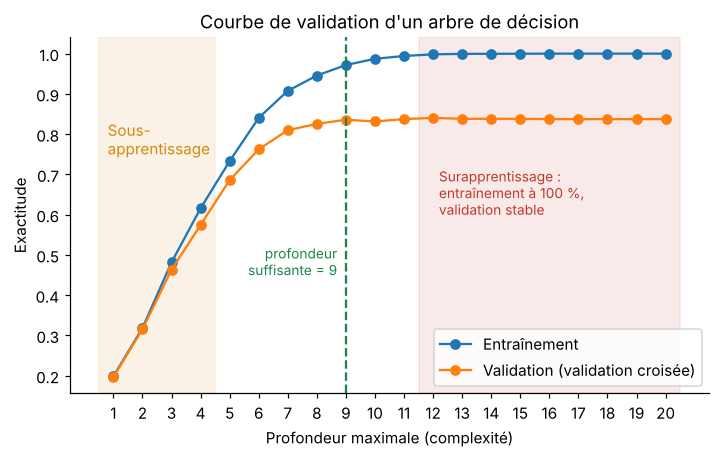

In [5]:
profondeurs = np.arange(1, 21)
sc_ent, sc_val = validation_curve(DecisionTreeClassifier(random_state=0), X_ent, y_ent,
                                  param_name="max_depth", param_range=profondeurs, cv=5)
moy_ent, moy_val = sc_ent.mean(axis=1), sc_val.mean(axis=1)
suffisante = profondeurs[int(np.argmax(moy_val >= moy_val.max() - 0.01))]
debut_sur = profondeurs[int(np.argmax(moy_ent >= 0.995))]

plt.figure(figsize=(7.5, 4.2))
plt.plot(profondeurs, moy_ent, "o-", label="Entraînement")
plt.plot(profondeurs, moy_val, "o-", label="Validation (validation croisée)")
plt.axvspan(0.5, 4.5, color="#d68910", alpha=0.10); plt.text(0.8, 0.75, "Sous-\napprentissage", color="#d68910")
plt.axvspan(debut_sur - 0.5, 20.5, color="#c0392b", alpha=0.10)
plt.text(debut_sur + 0.2, 0.6, "Surapprentissage :\nentraînement à 100 %,\nvalidation stable", color="#c0392b", fontsize=9)
plt.axvline(suffisante, color="#1e8449", ls="--")
plt.text(suffisante - 0.3, 0.45, f"profondeur\nsuffisante = {suffisante}", color="#1e8449", ha="right", fontsize=9)
plt.xlabel("Profondeur maximale (complexité)"); plt.ylabel("Exactitude"); plt.xticks(profondeurs)
plt.title("Courbe de validation d'un arbre de décision"); plt.legend(loc="lower right"); plt.show()

- **Faible complexité :** les deux scores sont bas ; le modèle est trop simple (**sous-apprentissage**).
- **Forte complexité :** l'entraînement atteint 100 %, mais la validation ne progresse plus ; l'écart traduit le **surapprentissage**.
- **Choix recommandé :** le modèle **le plus simple** qui atteint la meilleure performance de validation.

## 3. Une évaluation fiable : la validation croisée

Une seule séparation entraînement/validation donne une estimation qui dépend du hasard du découpage. La **validation croisée à k plis** :

1. divise l'ensemble d'entraînement en k sous-ensembles (plis) ;
2. entraîne k fois le modèle sur k − 1 plis et l'évalue sur le pli restant ;
3. rapporte la moyenne et l'écart-type des k scores.

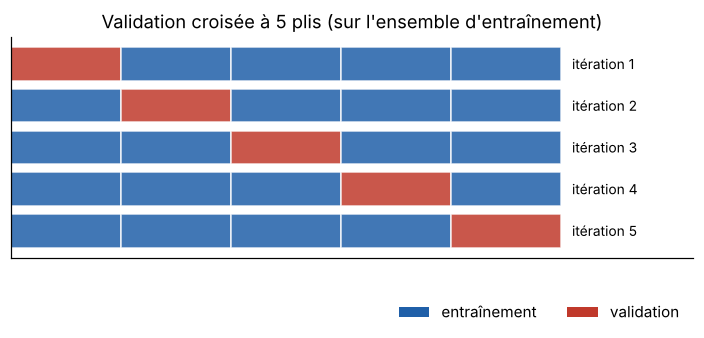

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.6))
for tour in range(5):
    for pli in range(5):
        ax.barh(tour, 1, left=pli, color="#c0392b" if pli == tour else "#1f5fa8", edgecolor="white", alpha=0.85)
    ax.text(5.1, tour, f"itération {tour + 1}", va="center", fontsize=9)
ax.set_yticks([]); ax.set_xticks([]); ax.invert_yaxis(); ax.set_xlim(0, 6.2)
ax.barh(0, 0, color="#1f5fa8", label="entraînement"); ax.barh(0, 0, color="#c0392b", label="validation")
ax.legend(loc="lower right", bbox_to_anchor=(1, -0.35), ncol=2, frameon=False)
ax.set_title("Validation croisée à 5 plis (sur l'ensemble d'entraînement)"); plt.show()

### Exercice 9 — Comparer quatre modèles par validation croisée

`cross_val_score(modele, X_ent, y_ent, cv=5)` renvoie les 5 scores. Affichez la moyenne et l'écart-type pour chaque modèle.

L'ensemble de test reste inutilisé jusqu'à l'évaluation finale.

**Corrigé**

In [7]:
candidats = {
    "Arbre de décision": DecisionTreeClassifier(random_state=0),
    "KNN (normalisé)": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=200, random_state=0),
}

resultats = {}
for nom, modele in candidats.items():
    scores = cross_val_score(modele, X_ent, y_ent, cv=5)
    resultats[nom] = scores
    print(f"{nom:<24} {scores.mean():.1%} ± {scores.std():.1%}")

Arbre de décision        83.7% ± 2.4%
KNN (normalisé)          96.9% ± 0.4%


Régression logistique    97.0% ± 0.5%


Forêt aléatoire          97.3% ± 0.3%


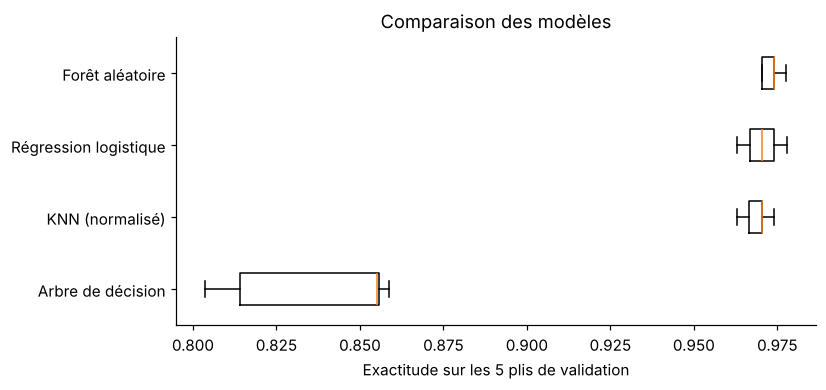

In [8]:
plt.figure(figsize=(7.5, 3.4))
plt.boxplot(list(resultats.values()), orientation="horizontal")
plt.yticks(range(1, len(resultats) + 1), list(resultats.keys()))
plt.xlabel("Exactitude sur les 5 plis de validation"); plt.title("Comparaison des modèles"); plt.show()

La **forêt aléatoire** agrège les votes de centaines d'arbres, chacun entraîné sur un échantillon différent des données et des variables. L'agrégation réduit fortement la variance d'un arbre isolé.

## 4. Choisir les hyperparamètres : `GridSearchCV`

`GridSearchCV` évalue chaque combinaison d'une grille d'hyperparamètres par validation croisée, retient la meilleure, puis réentraîne le modèle correspondant sur l'ensemble d'entraînement complet.

Dans un `Pipeline`, un hyperparamètre est désigné par `<nom de l'étape>__<paramètre>` (deux caractères de soulignement).

### Exercice 10 — Optimiser un KNN

**Corrigé**

In [9]:
pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier())
grille = {
    "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 15],
    "kneighborsclassifier__weights": ["uniform", "distance"],
}

recherche = GridSearchCV(pipeline, grille, cv=5)
recherche.fit(X_ent, y_ent)

print("Meilleurs hyperparamètres :", recherche.best_params_)
print(f"Exactitude en validation croisée : {recherche.best_score_:.1%}")

Meilleurs hyperparamètres : {'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__weights': 'distance'}
Exactitude en validation croisée : 97.3%


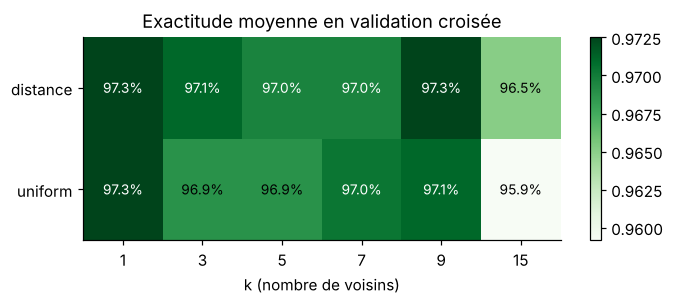

In [10]:
tableau = pd.DataFrame(recherche.cv_results_).pivot(
    index="param_kneighborsclassifier__weights", columns="param_kneighborsclassifier__n_neighbors",
    values="mean_test_score")
plt.figure(figsize=(7, 2.4))
plt.imshow(tableau.values, cmap="Greens", aspect="auto")
for i in range(tableau.shape[0]):
    for j in range(tableau.shape[1]):
        v = tableau.values[i, j]
        plt.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=9, color="white" if v > tableau.values.mean() else "black")
plt.xticks(range(tableau.shape[1]), tableau.columns); plt.yticks(range(tableau.shape[0]), tableau.index)
plt.xlabel("k (nombre de voisins)"); plt.title("Exactitude moyenne en validation croisée"); plt.colorbar(); plt.show()

### Évaluation finale

Le modèle et ses hyperparamètres étant fixés, on l'évalue **une seule fois** sur l'ensemble de test.

In [11]:
print(f"Exactitude finale sur l'ensemble de test : {recherche.score(X_test, y_test):.1%}")

Exactitude finale sur l'ensemble de test : 96.4%


## 5. Quantité de données : la courbe d'apprentissage

**Prédiction.** Comment évolue la performance de validation lorsque la taille de l'ensemble d'entraînement augmente ?

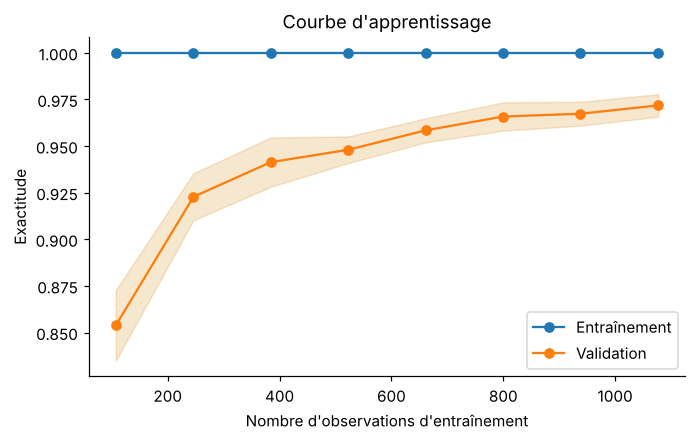

In [12]:
tailles, sc_ent_lc, sc_val_lc = learning_curve(recherche.best_estimator_, X_ent, y_ent, cv=5,
                                               train_sizes=np.linspace(0.1, 1.0, 8))
plt.figure(figsize=(7, 4))
plt.plot(tailles, sc_ent_lc.mean(axis=1), "o-", label="Entraînement")
plt.plot(tailles, sc_val_lc.mean(axis=1), "o-", label="Validation")
plt.fill_between(tailles, sc_val_lc.mean(1) - sc_val_lc.std(1), sc_val_lc.mean(1) + sc_val_lc.std(1), alpha=0.2, color="#d68910")
plt.xlabel("Nombre d'observations d'entraînement"); plt.ylabel("Exactitude")
plt.title("Courbe d'apprentissage"); plt.legend(loc="lower right"); plt.show()

Tant que la courbe de validation progresse, collecter davantage de données est un levier efficace. Lorsqu'elle plafonne, il faut agir sur le modèle lui-même ou sur les variables, par exemple avec des réseaux de neurones (atelier IA102).

In [13]:
quiz("Exactitude d'entraînement : 100 %. Exactitude de validation : 82 %. Quel est le diagnostic le plus probable ?",
     ["Sous-apprentissage", "Surapprentissage", "Modèle bien ajusté"],
     1, "L'écart important indique que le modèle ajuste le bruit : réduire la complexité ou augmenter les données.")

**Question de vérification.** Exactitude d'entraînement : 100 %. Exactitude de validation : 82 %. Quel est le diagnostic le plus probable ?

RadioButtons(layout=Layout(width='max-content'), options=('Sous-apprentissage', 'Surapprentissage', 'Modèle bi…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [14]:
quiz("Sur quelles données faut-il effectuer la recherche d'hyperparamètres ?",
     ["Sur l'ensemble de test", "Sur l'ensemble d'entraînement, par validation croisée", "Sur l'ensemble des données"],
     1, "Utiliser le test pour choisir les réglages conduirait à une estimation optimiste de la performance.")

**Question de vérification.** Sur quelles données faut-il effectuer la recherche d'hyperparamètres ?

RadioButtons(layout=Layout(width='max-content'), options=("Sur l'ensemble de test", "Sur l'ensemble d'entraîne…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

## À retenir

| Symptôme | Diagnostic | Action |
| --- | --- | --- |
| Scores d'entraînement et de validation faibles | Sous-apprentissage | Modèle plus complexe, meilleures variables |
| Entraînement élevé, validation nettement plus faible | Surapprentissage | Modèle plus simple, régularisation, plus de données |
| Variables d'échelles différentes | Distances biaisées | `StandardScaler` dans un `Pipeline` |
| Choix entre plusieurs modèles | Besoin d'une estimation fiable | `cross_val_score` |
| Choix des réglages | Hyperparamètres | `GridSearchCV` |
| Courbe de validation encore croissante | Données insuffisantes | Collecter davantage de données |

**Règle :** l'ensemble de test n'est utilisé qu'une fois, pour l'évaluation finale.

**Notebook suivant :** 5 — Détecter des structures dans les données.